QUESTION 3

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
bakery_data=pd.read_excel("Bakery.xlsx")
print(bakery_data.describe())
print(bakery_data.head())
print(bakery_data.columns)
print(bakery_data.shape)



       Day of Week       White       Wheat  Multigrain       Black  \
count    22.000000   22.000000   22.000000   22.000000   22.000000   
mean      3.863636  599.772727  530.409091  470.363636  383.590909   
std       1.934535  149.055097  107.023655  108.013026   81.951007   
min       1.000000  375.000000  352.000000  299.000000  256.000000   
25%       2.000000  498.500000  457.250000  403.750000  323.250000   
50%       4.000000  577.500000  503.000000  426.000000  362.500000   
75%       5.000000  703.000000  635.000000  568.500000  435.000000   
max       7.000000  875.000000  703.000000  644.000000  549.000000   

       Cinnamon Raisin  Sour Dough French   Light Oat  
count        22.000000          22.000000   22.000000  
mean        139.727273         127.090909  261.636364  
std          33.019737          28.683676   57.895263  
min          84.000000          88.000000  172.000000  
25%         116.500000         104.000000  224.000000  
50%         137.500000         12

In [4]:
#I am using the describe method because it gives us the mean of every bread type so
bakery_data.describe()
bread_types=bakery_data.drop(columns=["Day of Week"])
means=bread_types.mean().sort_values(ascending=False)

print(means.round(2))


White                599.77
Wheat                530.41
Multigrain           470.36
Black                383.59
Light Oat            261.64
Cinnamon Raisin      139.73
Sour Dough French    127.09
dtype: float64


<function matplotlib.pyplot.show(close=None, block=None)>

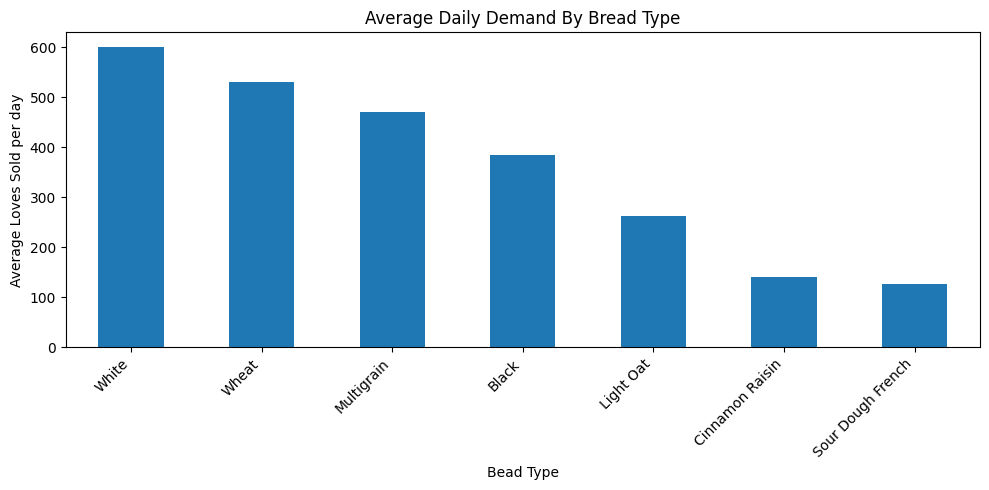

In [5]:
means.plot(kind="bar",figsize=(10,5))

plt.title("Average Daily Demand By Bread Type")
plt.xlabel("Bead Type")
plt.ylabel("Average Loves Sold per day")
plt.xticks(rotation=45,ha="right")
plt.tight_layout()
plt.show

In [15]:
bread_types.head()
print(bread_types["White"].max())
print(bread_types["White"].min())

print(bread_types["Wheat"].max())
print(bread_types["Wheat"].min())

print(bread_types["Multigrain"].max())
print(bread_types["Multigrain"].min())

print(bread_types["Black"].max())
print(bread_types["Black"].min())

print(bread_types["Light Oat"].max())
print(bread_types["Light Oat"].min())

print(bread_types["Cinnamon Raisin"].max())
print(bread_types["Cinnamon Raisin"].min())

print(bread_types["Sour Dough French"].min())
print(bread_types["Sour Dough French"].max())

White_Intervals=[375,475,575,675,775,875]
white_Freq=pd.cut(bread_types["White"],bins=White_Intervals,right=True,include_lowest=True).value_counts().sort_index()
print(white_Freq)
print("Total observations:", white_Freq.sum())


875
375
703
352
644
299
549
256
356
172
201
84
88
188
White
(374.999, 475.0]    5
(475.0, 575.0]      6
(575.0, 675.0]      4
(675.0, 775.0]      3
(775.0, 875.0]      4
Name: count, dtype: int64
Total observations: 22


In [16]:
for bread in bread_types.columns:
    bins = np.linspace(
        bread_types[bread].min(),
        bread_types[bread].max(),
        6
    )

    freq = pd.cut(
        bread_types[bread],
        bins=bins,
        include_lowest=True
    ).value_counts().sort_index()

    print(f"\n{bread}")
    print(freq)
    print("Total observations:", freq.sum())


White
White
(374.999, 475.0]    5
(475.0, 575.0]      6
(575.0, 675.0]      4
(675.0, 775.0]      3
(775.0, 875.0]      4
Name: count, dtype: int64
Total observations: 22

Wheat
Wheat
(351.999, 422.2]    3
(422.2, 492.4]      6
(492.4, 562.6]      4
(562.6, 632.8]      3
(632.8, 703.0]      6
Name: count, dtype: int64
Total observations: 22

Multigrain
Multigrain
(298.999, 368.0]    3
(368.0, 437.0]      9
(437.0, 506.0]      1
(506.0, 575.0]      4
(575.0, 644.0]      5
Name: count, dtype: int64
Total observations: 22

Black
Black
(255.999, 314.6]    5
(314.6, 373.2]      7
(373.2, 431.8]      4
(431.8, 490.4]      3
(490.4, 549.0]      3
Name: count, dtype: int64
Total observations: 22

Cinnamon Raisin
Cinnamon Raisin
(83.999, 107.4]    5
(107.4, 130.8]     4
(130.8, 154.2]     7
(154.2, 177.6]     3
(177.6, 201.0]     3
Name: count, dtype: int64
Total observations: 22

Sour Dough French
Sour Dough French
(87.999, 108.0]    8
(108.0, 128.0]     4
(128.0, 148.0]     6
(148.0, 168.0] 

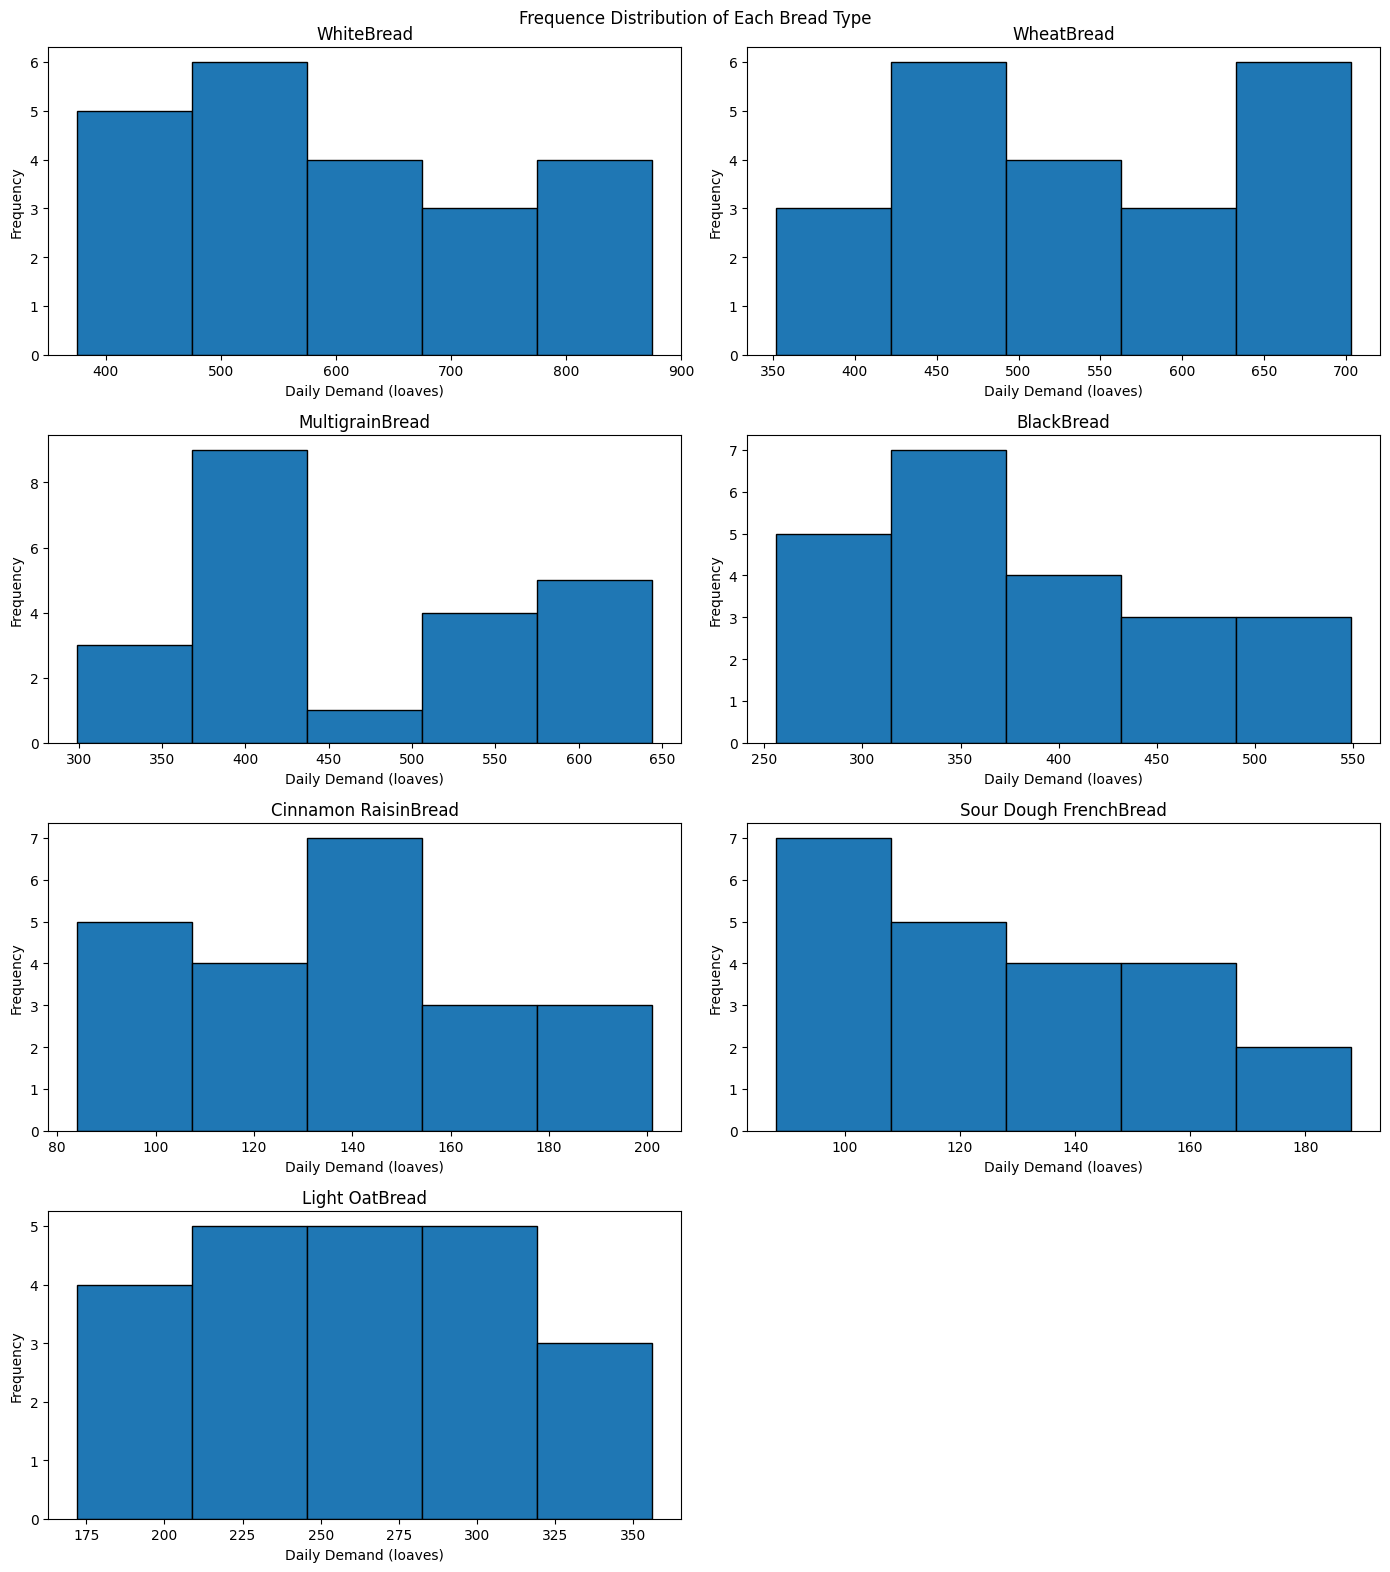

In [ ]:
#so fig is the whole page and the axes are the subboxes inside that page

bread_colums=bread_types.columns
fig,axes=plt.subplots(4,2, figsize=(14,16))
axes=axes.flatten()

#we used for loop here to create a seperate histogram against each bread type and we used axes index
# to plot the histogram on the subplots axis that we just created

for i,breads in enumerate(bread_colums):
    axes[i].hist(bread_types[breads],bins=5,edgecolor="black")

    axes[i].set_title(f"{breads}Bread")
    axes[i].set_xlabel("Daily Demand (loaves)")
    axes[i].set_ylabel("Frequency")

#to not show the unused eight row in the plot
axes[-1].set_visible(False)
plt.suptitle("Frequence Distribution of Each Bread Type")
plt.tight_layout()
plt.show()


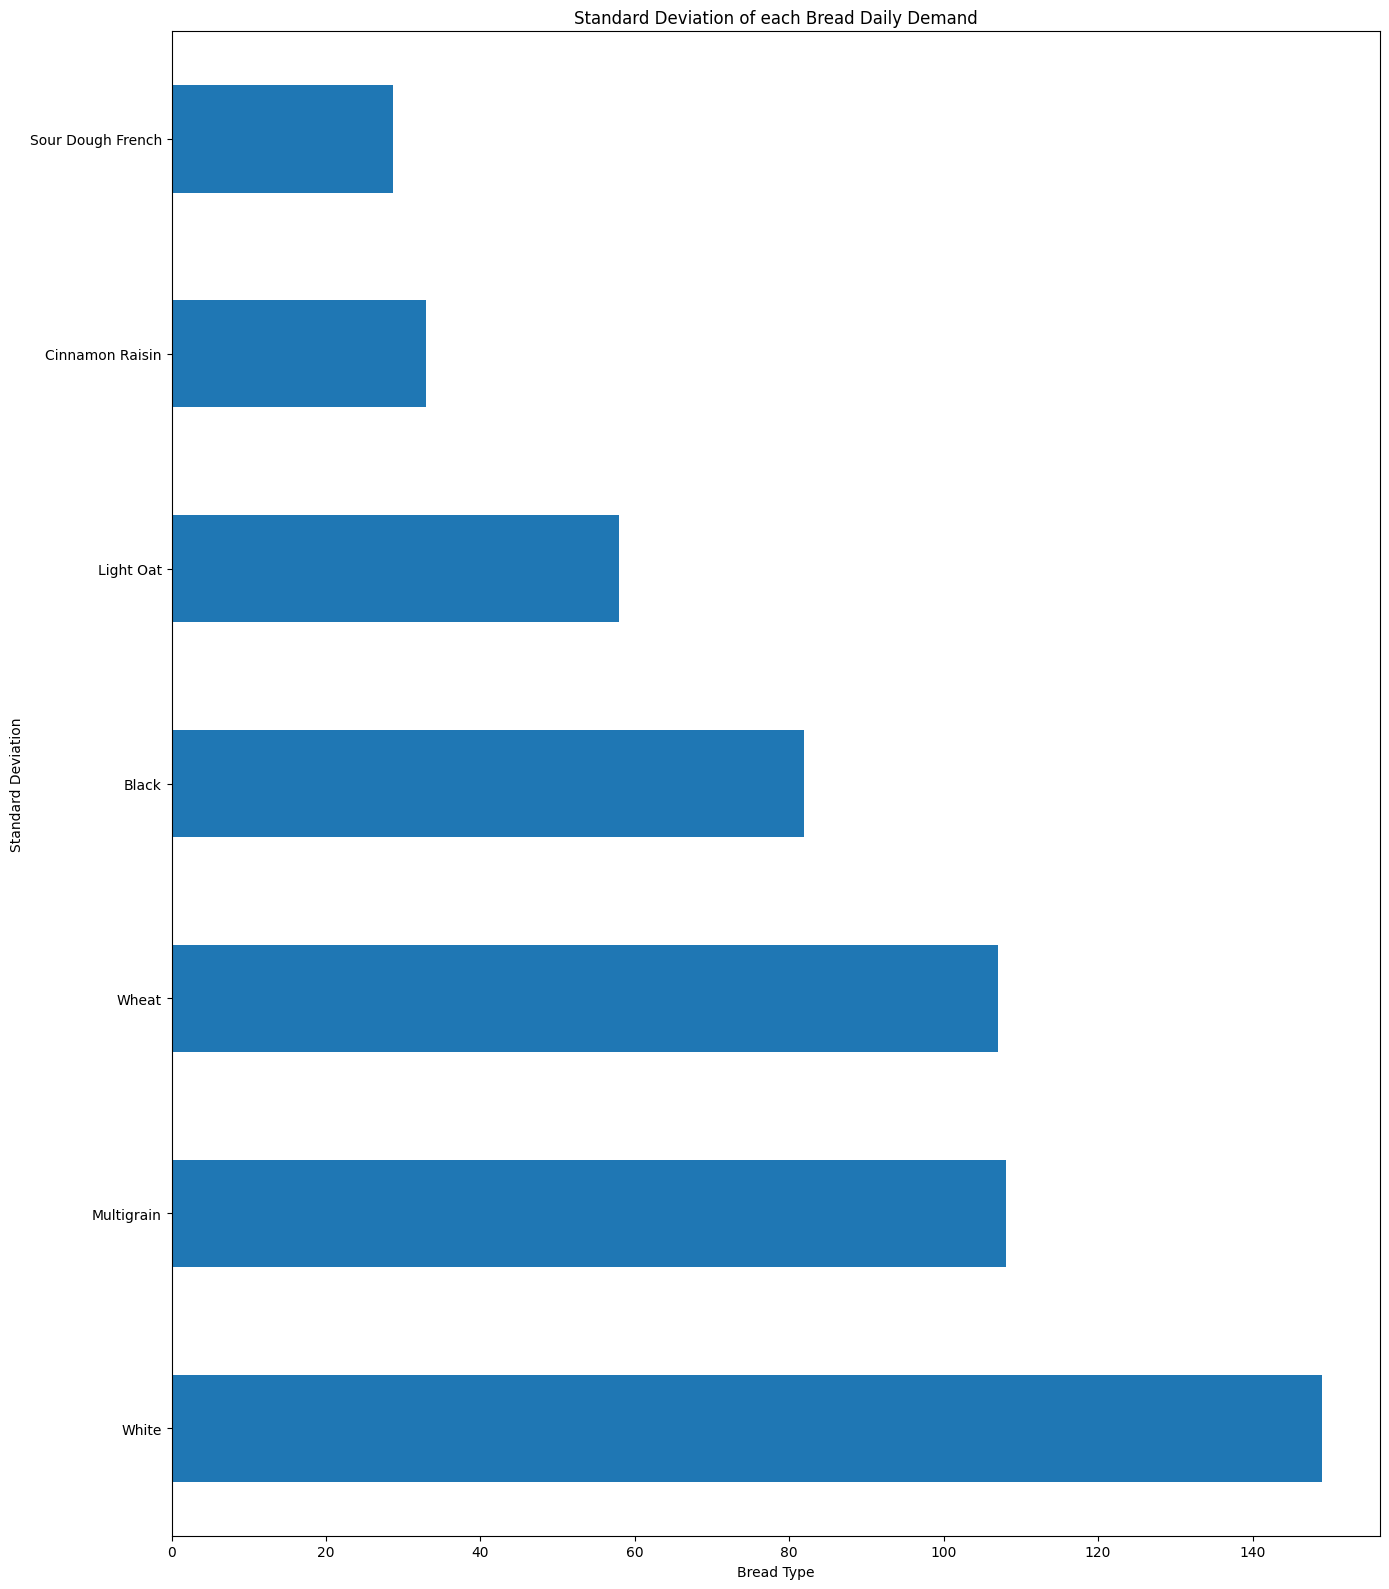

In [22]:
# QUestion 3 c part
std_dev=bread_types.std().sort_values(ascending=False)

std_dev.plot(kind="barh", figsize=(14,16))
plt.title("Standard Deviation of each Bread Daily Demand")
plt.xlabel("Bread Type")
plt.ylabel("Standard Deviation")
plt.tight_layout()
plt.show()

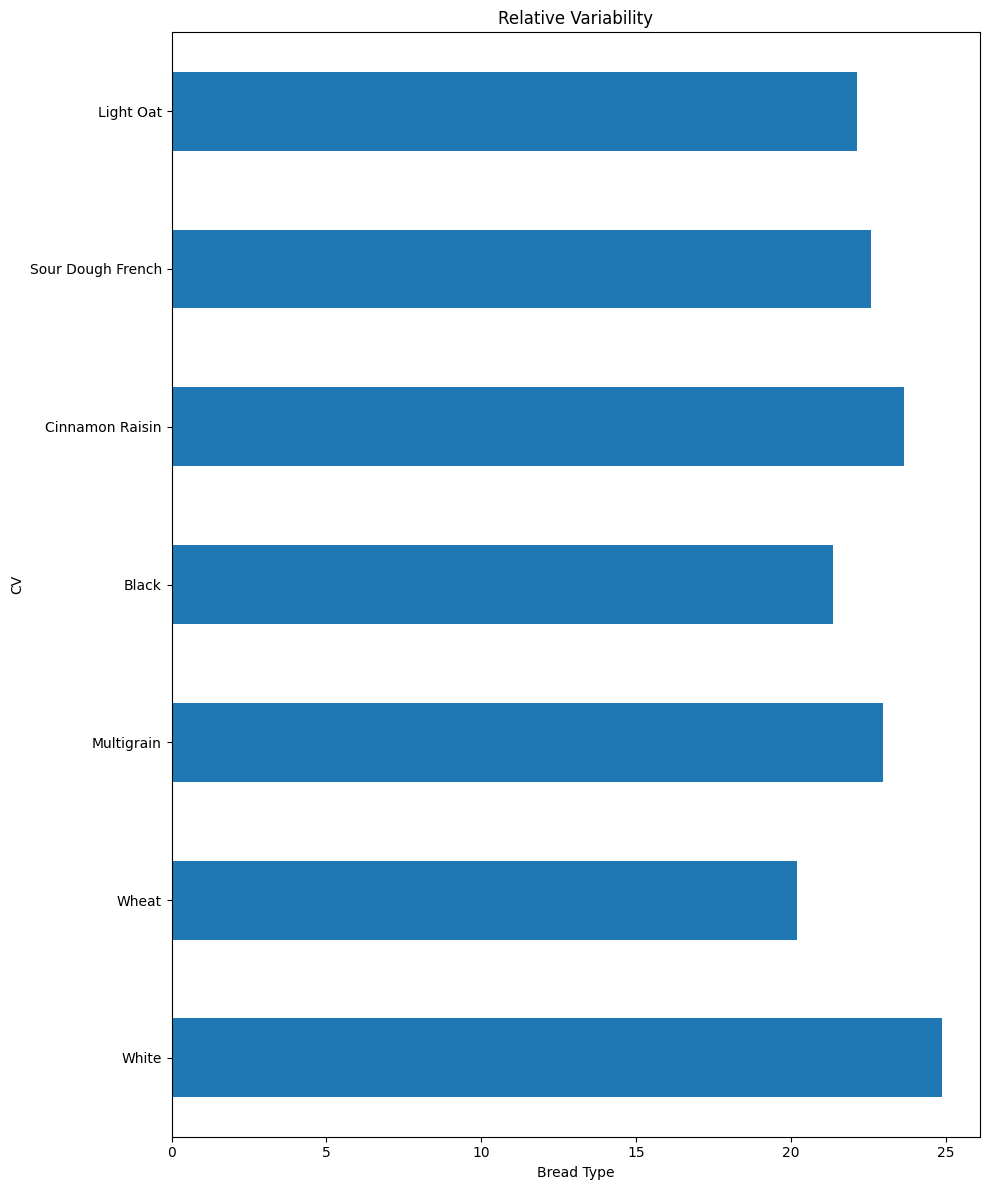

In [24]:
cv=[]

for i,breads in enumerate(bread_colums):
    cv.append(bread_types[breads].std()/bread_types[breads].mean()*100)

cv=pd.Series(cv,index=bread_colums)
cv.plot(kind="barh",figsize=(10,12))
plt.title("Relative Variability")
plt.xlabel("Bread Type")
plt.ylabel("CV")
plt.tight_layout()
plt.show()

In [ ]:
#Question 3 Part e:
bakery_data["Total Loaves Sold"]=bread_types.sum(axis=1)


avg_by_day = bakery_data.groupby("Day of Week")["Total Loaves Sold"].mean()

print("So the Day of the week with the highest Average is : ",avg_by_day.idxmax(),"\n")
print("With the Average of : ",avg_by_day.max(),"\n")

So the Day of the week with the highest Average is :  6 

With the Average of :  3116.5 

